In [39]:
## On how to build covariance and fisher forecast.
import numpy as np  #numpy: https://numpy.org/doc/stable/index.html
import importlib.util  #importlib: https://docs.python.org/3/library/importlib.html
from scipy.spatial import cKDTree
from astropy.table import Table
from numpy.lib import recfunctions as rfn
import matplotlib
import matplotlib.pyplot as plt
import time

import os, sys
root = "/mnt/home/project/csatsangi.chetan/projects"
sys.path.insert(0, os.path.join(root, "sahyadri-sandbox", "scripts", "post-process"))
sys.path.insert(0, os.path.join(root, "Derivatives"))

In [40]:
from hod_utils import HODFits_BGS

In [2]:
jackknife_vvf_100 = Table.read(root + '/JackKnife/rsd_results/vvf_results_100.fits').as_array()

In [3]:
vvf_realizations = jackknife_vvf_100['vvf_realizations']
njn = vvf_realizations.shape[1]

# 1. Calculate the mean across the jackknife regions (shape: n_percentiles)
vvf_mean_jn = np.mean(vvf_realizations, axis=1)

# 2. Calculate the deviations from the mean (shape: n_percentiles, njn)
# The [:, None] broadcasts the 1D mean array across the njn columns
delta = vvf_realizations - vvf_mean_jn[:, None]

# 3. Compute the Jackknife covariance matrix (shape: n_percentiles, n_percentiles)
cov_matrix = ((njn - 1) / njn) * (delta @ delta.T)

# 4. Invert to get the precision matrix
C_inv = np.linalg.inv(cov_matrix)

$$\mathbf{F} = \underbrace{\mathbf{D}^T}_{(m+n) \times p} \times \underbrace{\mathbf{C}^{-1}}_{p \times p} \times \underbrace{\mathbf{D}}_{p \times (m+n)}$$

In [42]:
hod_fits = HODFits_BGS()
hod_params_dict = hod_fits.get_hod_params_dict(-18.0)

In [26]:
root = "/mnt/home/project/csatsangi.chetan/projects"
suff = "rsd" # or 'real'

# 1. Read HOD derivatives
hod_params = ['alpha', 'kappa', 'sigma', 'logM1', 'logMcut']
hod_derivs = []
for p in hod_params:
    tab = Table.read(f'{root}/Derivatives/derivatives/5/dVVF_d{p}_{suff}.fits')
    hod_derivs.append(tab[f'dVVF_d{p}'].data)

# 2. Read Cosmological derivatives
cosmo_params = ['Om', 'ns', 'h', 'As']
cosmo_derivs = []
for p in cosmo_params:
    tab = Table.read(f'{root}/Derivatives/derivatives/cosmo/dVVF_d{p}_{suff}.fits')
    cosmo_derivs.append(tab[f'dVVF_d{p}'].data)

# 3. Stack into the joint Jacobian D (shape: p x 9)
# Order: [alpha, kappa, sigma, logM1, logMcut, Om, ns, h, As]
D_joint = np.column_stack((*hod_derivs, *cosmo_derivs))

In [27]:
D_joint

array([[-7.55436371e-02, -1.11696293e+01,  1.40733360e-02,
         5.52620422e-02, -2.30258509e-02, -4.14276609e-02,
         4.14550731e-03, -3.26603325e-02, -6.90838058e+06],
       [-1.69973183e-01, -1.11696293e+01,  8.44400159e-02,
         1.22037010e-01, -5.52620422e-02, -7.32950924e-02,
         3.62731889e-02, -1.00950119e-01, -1.88193816e+07],
       [-1.85261777e-01,  1.11696293e+01,  8.44400159e-02,
         1.72693882e-01, -6.90775528e-02,  1.43403442e-02,
         1.97947974e-01, -6.82897862e-02, -2.38220020e+07],
       [ 3.05771864e-02, -5.58481467e+01, -2.09411239e-01,
         7.13801379e-02,  1.82733153e-01,  1.91204589e-02,
         2.17431858e-01, -5.34441805e-04, -3.33508028e+06],
       [ 1.42404252e+00, -6.52585595e+02, -3.22209027e+00,
        -2.02103650e+00,  1.05515962e-01,  1.03290312e+00,
        -2.05855529e+00,  7.23055226e-01,  1.03435133e+08]])

In [43]:
# Assuming C_inv is your Jackknife precision matrix (shape: p x p)
# F_joint shape will be (9, 9)
# 1. Define your fiducial values in the exact order of your Jacobian columns
# 2. Extract values and convert linear masses to log-masses
fid_alpha = hod_params_dict['alpha']
fid_kappa = hod_params_dict['kappa']
fid_sigma = hod_params_dict['sigma']
fid_logM1 = np.log10(hod_params_dict['M1'])
fid_logMcut = np.log10(hod_params_dict['Mcut'])

# 3. Combine with fiducial cosmological parameters 
# ORDER MUST MATCH YOUR JACOBIAN COLUMNS: [alpha, kappa, sigma, logM1, logMcut, Om, ns, h, As]
fiducial_vals = np.array([
    fid_alpha, 
    fid_kappa, 
    fid_sigma, 
    fid_logM1, 
    fid_logMcut, 
    0.3138,    # Om
    0.9649,    # ns
    0.6736,    # h
    2.0989e-9  # As
])

# 2. Scale the Jacobian matrix D_joint
# Multiplying column j by fiducial_vals[j] converts dVVF/d(theta) into dVVF/d(ln_theta)
D_scaled = D_joint * fiducial_vals

# 3. Compute the scaled Fisher matrix
F_scaled = D_scaled.T @ C_inv @ D_scaled

cond_number = np.linalg.cond(F_scaled)
print(f"Scaled Condition Number: {cond_number:.2e}")

Scaled Condition Number: 1.15e+19


In [50]:
# 4. Invert using the pseudo-inverse (pinv) for numerical stability
F_inv_scaled = np.linalg.pinv(F_scaled, rcond=1e-10)

# 5. Extract the fractional 1-sigma errors and scale them back to absolute errors
fractional_errors = np.sqrt(np.diag(F_inv_scaled))
sigma_errors = fractional_errors * fiducial_vals

# 6. Print final constraints
param_names = ['alpha', 'kappa', 'sigma', 'logM1', 'logMcut', 'Om', 'ns', 'h', 'As']
print("\n--- 1-Sigma Errors (VVF Only) ---")
for name, err, fid in zip(param_names, sigma_errors, fiducial_vals):
    print(f"{name:8s}: {err:.6e}  (Fiducial: {fid:.4e})")


--- 1-Sigma Errors (VVF Only) ---
alpha   : 3.760268e-01  (Fiducial: 1.1119e+00)
kappa   : 5.040835e-06  (Fiducial: 8.9528e-05)
sigma   : 1.251869e-02  (Fiducial: 7.1056e-02)
logM1   : 3.333994e-01  (Fiducial: 1.2453e+01)
logMcut : 2.868172e-01  (Fiducial: 1.1154e+01)
Om      : 5.749423e-02  (Fiducial: 3.1380e-01)
ns      : 9.145456e-02  (Fiducial: 9.6490e-01)
h       : 8.622027e-02  (Fiducial: 6.7360e-01)
As      : 3.464777e-10  (Fiducial: 2.0989e-09)


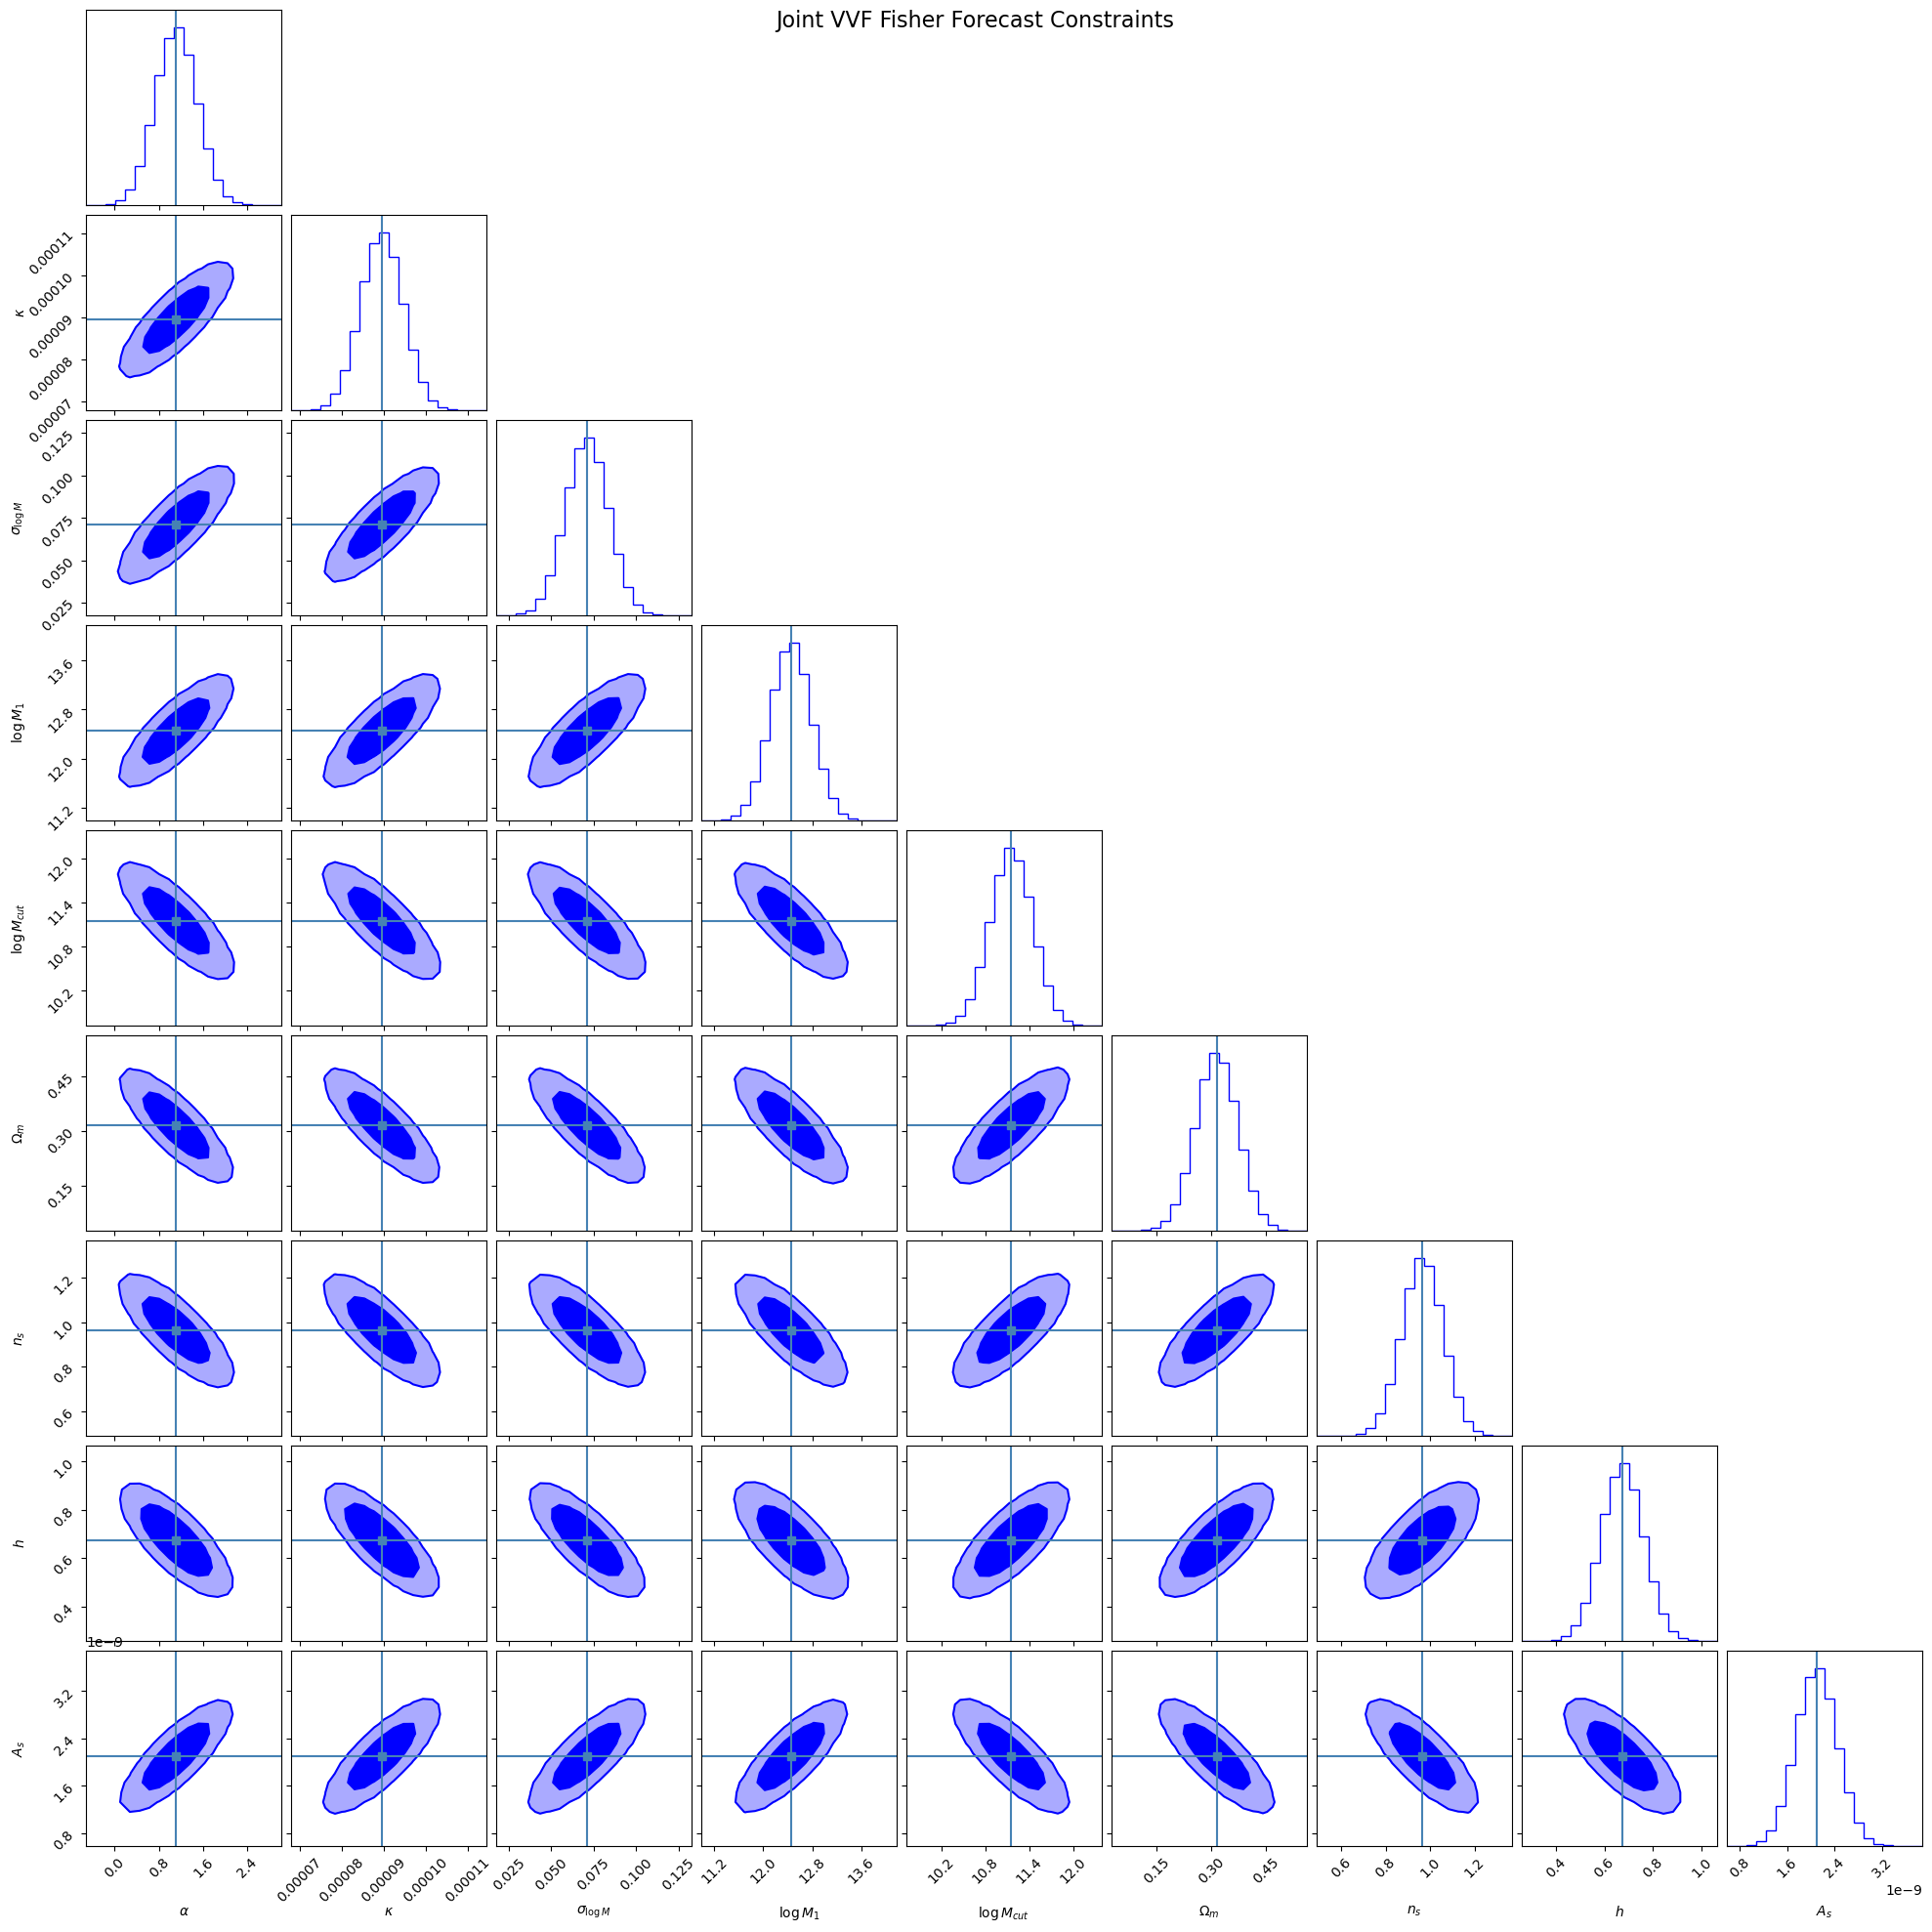

In [51]:
import corner
import matplotlib.pyplot as plt

# Convert the fractional covariance matrix back to the absolute parameter scale
# Absolute Covariance = Fractional Covariance * (Fiducial_i * Fiducial_j)
F_inv_abs = F_inv_scaled * np.outer(fiducial_vals, fiducial_vals)

# Define fiducial center values for sampling
labels = [r'$\alpha$', r'$\kappa$', r'$\sigma_{\log M}$', r'$\log M_1$', r'$\log M_{cut}$', 
          r'$\Omega_m$', r'$n_s$', r'$h$', r'$A_s$']

# Draw Gaussian samples
samples_joint = np.random.multivariate_normal(fiducial_vals, F_inv_abs, size=100000)

fig = corner.corner(
    samples_joint,
    labels=labels,
    truths=fiducial_vals,
    levels=(0.6827, 0.9545),
    color='blue',
    plot_datapoints=False,
    fill_contours=True,
    smooth=1.0
)

plt.suptitle("Joint VVF Fisher Forecast Constraints", fontsize=16)
plt.savefig("joint_vvf_corner_plot.png", dpi=300)
plt.show()